# Lab 2: PID Controller for Robot Navigation

This notebook contains code to load and visualize robot trajectory data from the runs directory.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import json
import os

## Reference Trajectory

In [2]:
# Reference curves from planner.py: (label, y(x), x_max), sampled into 30 waypoints like the planner.
# The sigmoid was changed mid-lab (commit 0d5d44e): the first sigmoid run used the lab-spec curve,
# later runs used the stretched one. params.json doesn't record which, so keep both and pick the closer.
REFERENCE_CURVES = {
    "parabola": [
        ("$y = x^2$", lambda x: x**2, 1.5),
    ],
    "sigmoid": [
        ("$y = 2/(1+e^{-2x}) - 1$", lambda x: 2 / (1 + np.exp(-2 * x)) - 1, 2.5),
        ("$y = 2/(1+e^{-x}) - 1$", lambda x: 2 / (1 + np.exp(-x)) - 1, 4.0),
    ],
}

def reference_path(run_path, x_robot, y_robot, num_points=30):
    """Return (ref_x, ref_y, label) for the path the planner commanded in this run."""
    with open(os.path.join(run_path, "params.json")) as f:
        params = json.load(f)

    # Point runs have no path, only a goal
    if params["motion"] == "point":
        gx, gy = params["goal"]
        return np.array([gx]), np.array([gy]), f"goal ({gx}, {gy})"

    best = None
    for label, curve, x_max in REFERENCE_CURVES[params["trajectory"]]:
        ref_x = np.linspace(0.0, x_max, num_points)
        ref_y = curve(ref_x)
        # Mean distance from each robot pose to its nearest reference waypoint
        dist = np.hypot(x_robot[:, None] - ref_x, y_robot[:, None] - ref_y).min(axis=1).mean()
        if best is None or dist < best[0]:
            best = (dist, ref_x, ref_y, f"{label}, x in [0, {x_max}]")
    return best[1:]

## Runs

In [3]:
# Runs to plot, keyed by controller (paths are relative to this notebook's folder, lab2/).
# Both follow the parabola with the same P gains (klp=0.2, kap=1.0). The P run used a tighter
# final-goal tolerance (0.01 vs 0.05 m), so it runs a little longer at the end of the path.
RUN_PATHS = {
    "PID": "runs_submit/trajectory_parabola_PID_20261028-181744/",
    "P": "runs_submit/trajectory_parabola_P_20261028-173605/",
}

def read_csv(path):
    # Log headers are "x, y, theta, stamp, " -> strip the spaces and drop the empty trailing column
    df = pd.read_csv(path, skipinitialspace=True)
    return df.loc[:, ~df.columns.str.startswith('Unnamed')]

def load_run(run_path):
    """Load a run's robot_pose.csv and the reference path the planner commanded for it."""
    df = read_csv(os.path.join(run_path, "robot_pose.csv"))
    x, y = df['x'].values, df['y'].values
    ref_x, ref_y, ref_label = reference_path(run_path, x, y)
    return {'path': run_path, 'x': x, 'y': y, 'theta': df['theta'].values, 'stamp': df['stamp'].values,
            'ref_x': ref_x, 'ref_y': ref_y, 'ref_label': ref_label}

runs = {name: load_run(path) for name, path in RUN_PATHS.items()}
for name, run in runs.items():
    print(f"{name}: {os.path.basename(os.path.normpath(run['path']))} -> reference {run['ref_label']}")

PID: trajectory_parabola_PID_20261028-181744 -> reference $y = x^2$, x in [0, 1.5]
P: trajectory_parabola_P_20261028-173605 -> reference $y = x^2$, x in [0, 1.5]


## Position Plot

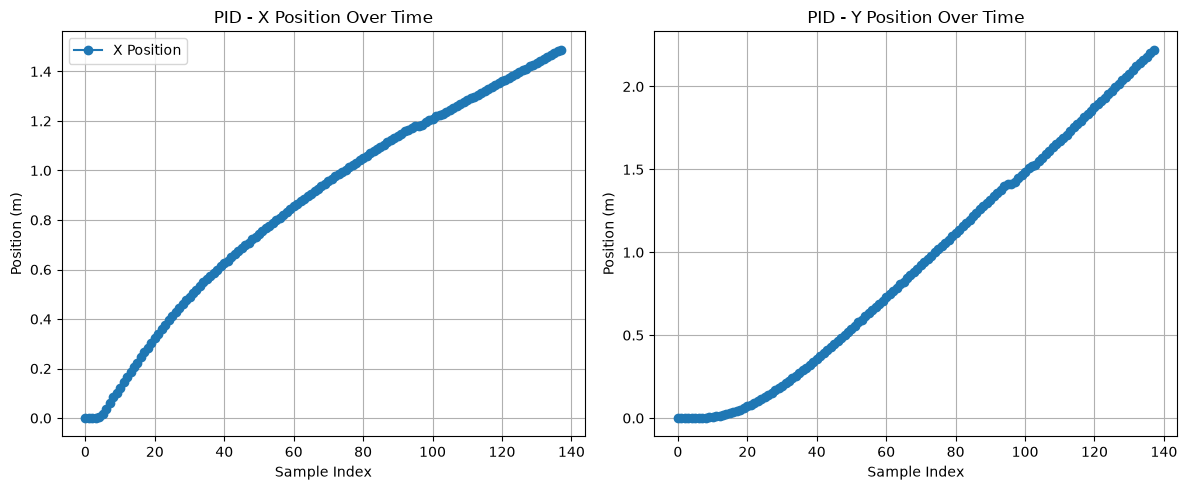

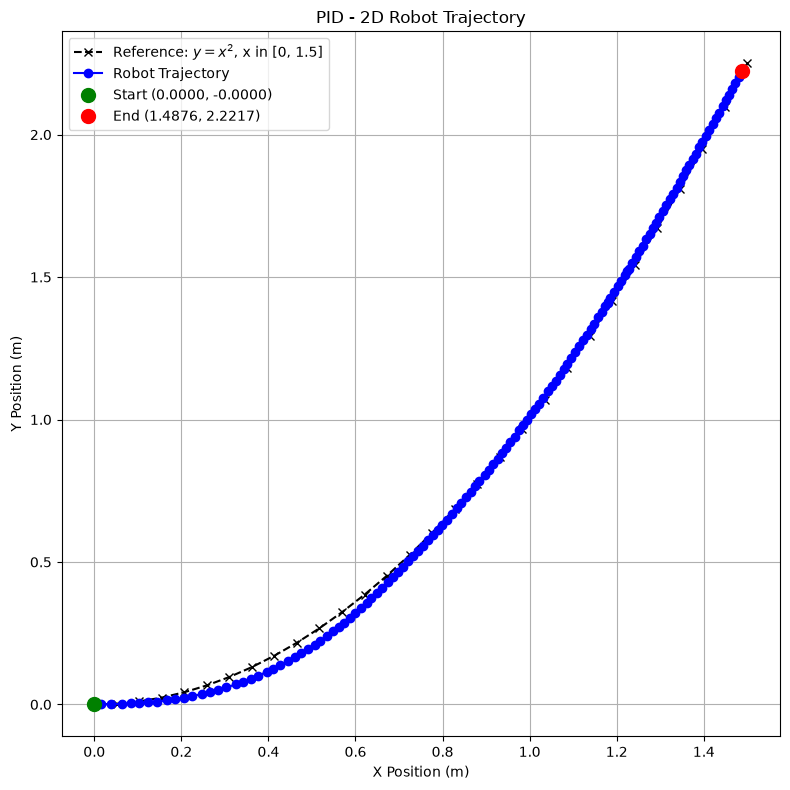

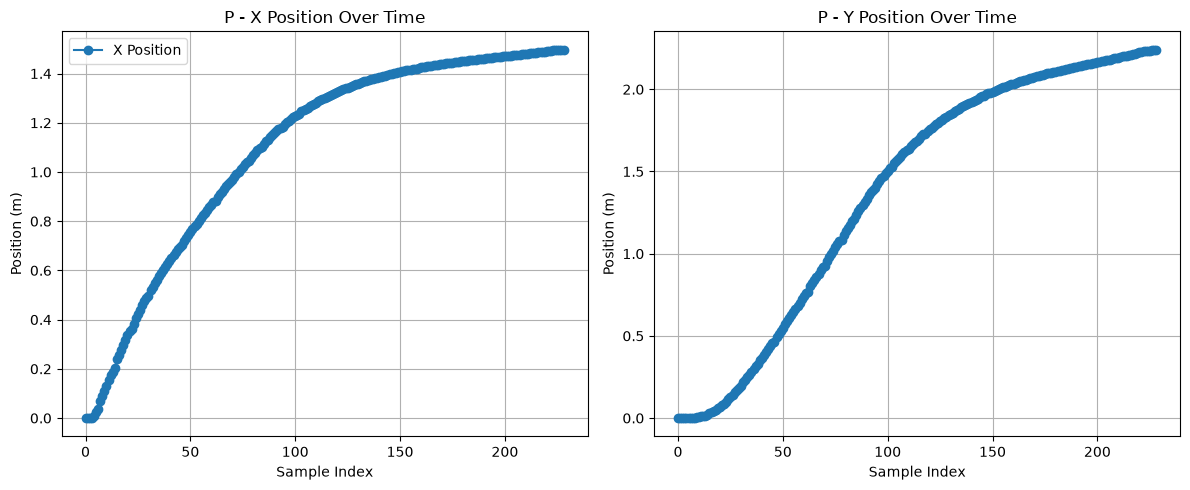

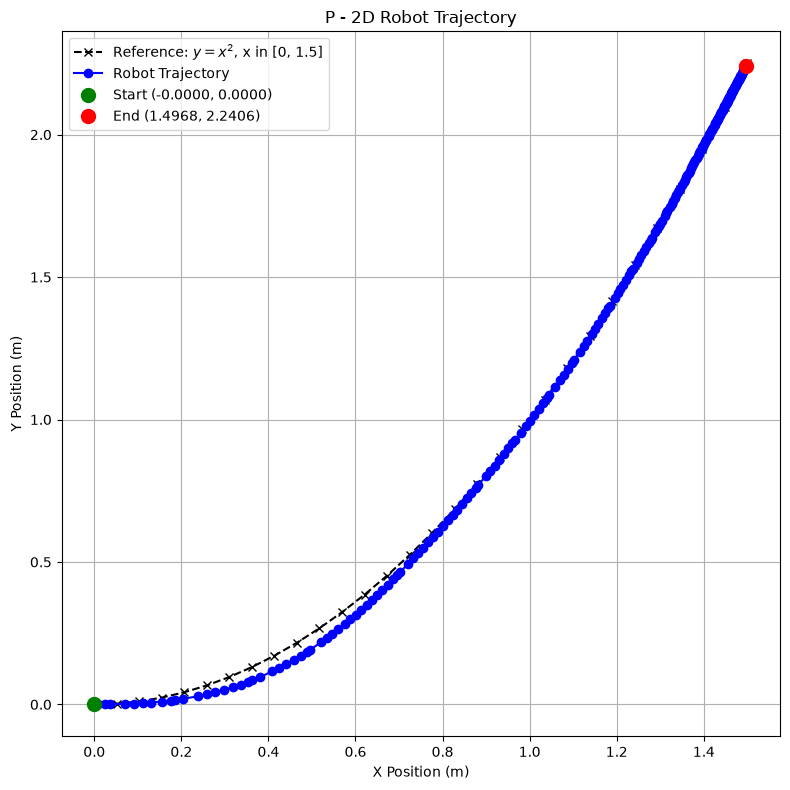

In [4]:
for name, run in runs.items():
    x_positions, y_positions = run['x'], run['y']

    # Create position plot (x vs y)
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    # Plot x and y positions
    ax[0].plot(x_positions, label='X Position', marker='o')
    ax[0].set_xlabel('Sample Index')
    ax[0].set_ylabel('Position (m)')
    ax[0].set_title(f'{name} - X Position Over Time')
    ax[0].grid(True)
    ax[0].legend()

    # Plot y position
    ax[1].plot(y_positions, marker='o')
    ax[1].set_xlabel('Sample Index')
    ax[1].set_ylabel('Position (m)')
    ax[1].set_title(f'{name} - Y Position Over Time')
    ax[1].grid(True)

    plt.tight_layout()
    plt.show()

    # Create 2D trajectory plot
    fig, ax = plt.subplots(1, figsize=(8, 8))

    ax.plot(run['ref_x'], run['ref_y'], 'k--', marker='x', label=f"Reference: {run['ref_label']}")
    ax.plot(x_positions, y_positions, 'b-', marker='o', label='Robot Trajectory')
    ax.set_xlabel('X Position (m)')
    ax.set_ylabel('Y Position (m)')
    ax.set_title(f'{name} - 2D Robot Trajectory')
    ax.grid(True)
    ax.legend()

    # Add start and end markers
    ax.plot(x_positions[0], y_positions[0], 'go', markersize=10, label=f'Start ({x_positions[0]:.4f}, {y_positions[0]:.4f})')
    ax.plot(x_positions[-1], y_positions[-1], 'ro', markersize=10, label=f'End ({x_positions[-1]:.4f}, {y_positions[-1]:.4f})')
    ax.legend()

    plt.tight_layout()
    plt.show()

## Heading Plot

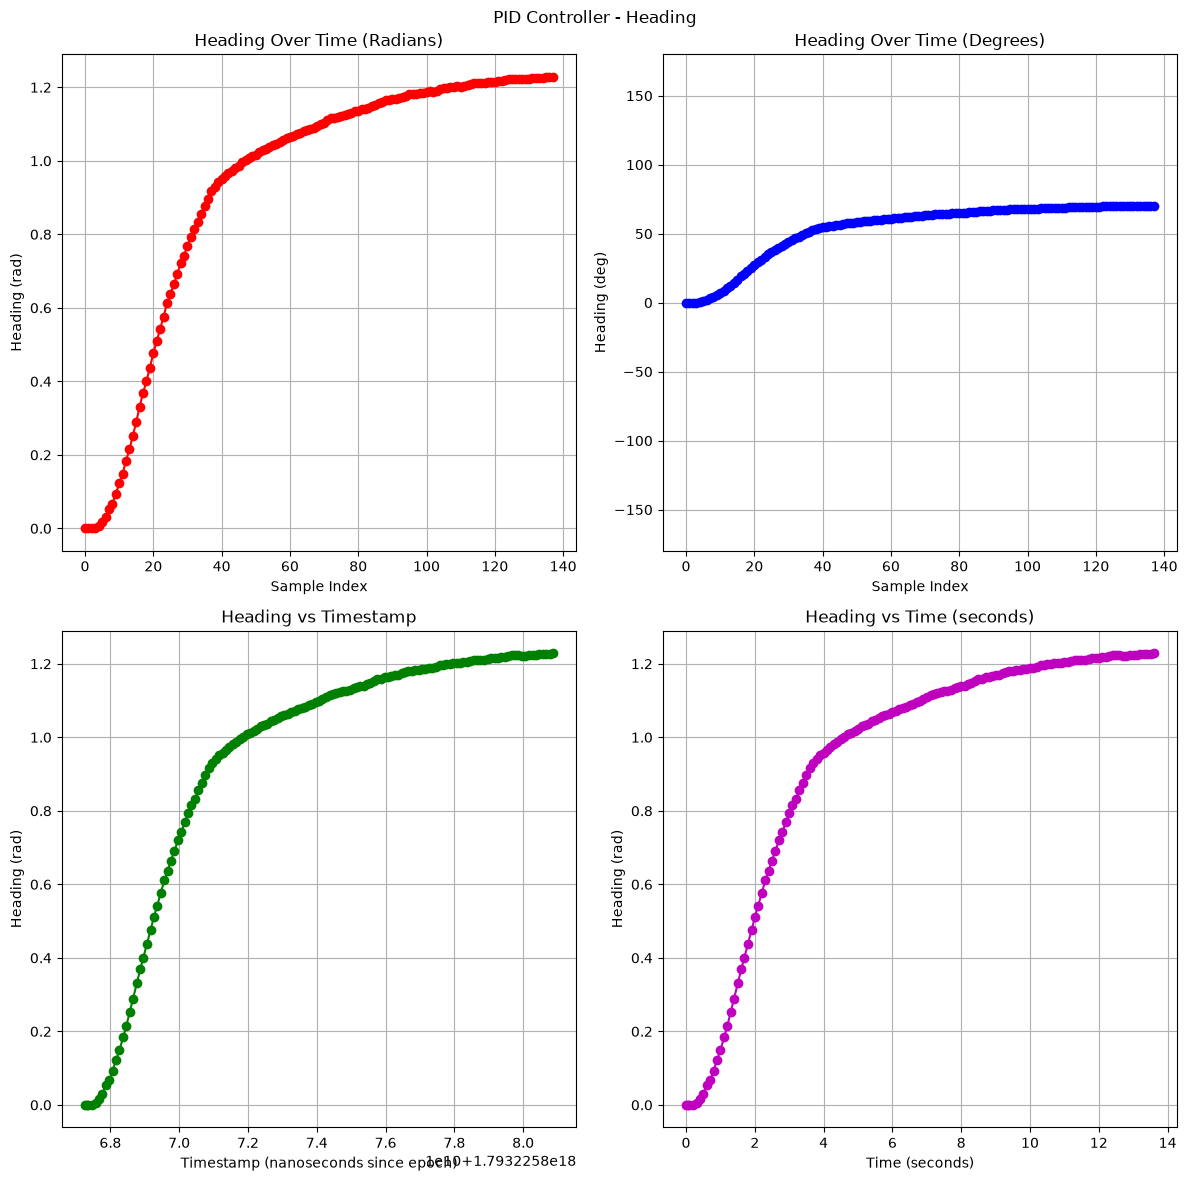

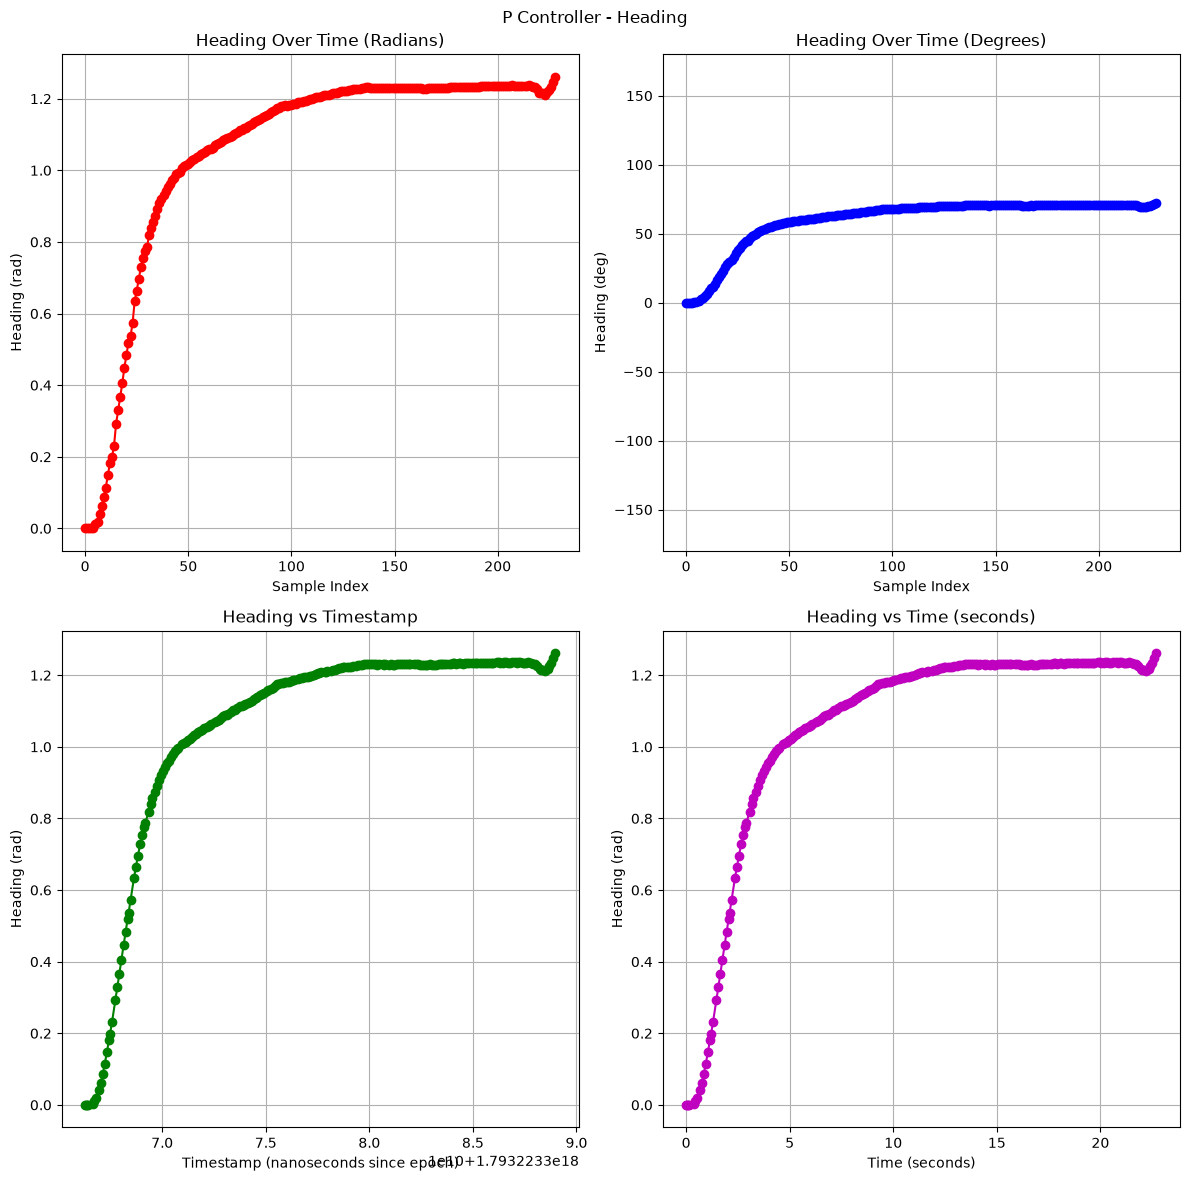

In [5]:
for name, run in runs.items():
    # Extract heading (theta) data
    theta = run['theta']

    # Create heading plot
    fig, axs = plt.subplots(2, 2, figsize=(12, 12))
    fig.suptitle(f'{name} Controller - Heading')

    # Plot theta in radians (raw)
    axs[0, 0].plot(theta, 'r-', marker='o')
    axs[0, 0].set_xlabel('Sample Index')
    axs[0, 0].set_ylabel('Heading (rad)')
    axs[0, 0].set_title('Heading Over Time (Radians)')
    axs[0, 0].grid(True)

    # Convert theta to degrees
    theta_deg = np.degrees(theta)

    # Plot heading in degrees
    axs[0, 1].plot(theta_deg, 'b-', marker='o')
    axs[0, 1].set_xlabel('Sample Index')
    axs[0, 1].set_ylabel('Heading (deg)')
    axs[0, 1].set_title('Heading Over Time (Degrees)')
    axs[0, 1].grid(True)
    axs[0, 1].set_ylim(-180, 180)

    # Plot heading vs time in seconds
    stamp = run['stamp']
    axs[1, 0].plot(stamp, theta, 'g-', marker='o')
    axs[1, 0].set_xlabel('Timestamp (nanoseconds since epoch)')
    axs[1, 0].set_ylabel('Heading (rad)')
    axs[1, 0].set_title('Heading vs Timestamp')
    axs[1, 0].grid(True)

    # Plot heading vs time in seconds (relative to the first sample)
    timestamp_sec = (stamp - stamp[0]) / 1e9
    axs[1, 1].plot(timestamp_sec, theta, 'm-', marker='o')
    axs[1, 1].set_xlabel('Time (seconds)')
    axs[1, 1].set_ylabel('Heading (rad)')
    axs[1, 1].set_title('Heading vs Time (seconds)')
    axs[1, 1].grid(True)

    plt.tight_layout()
    plt.show()

## Combined Position and Heading Plot

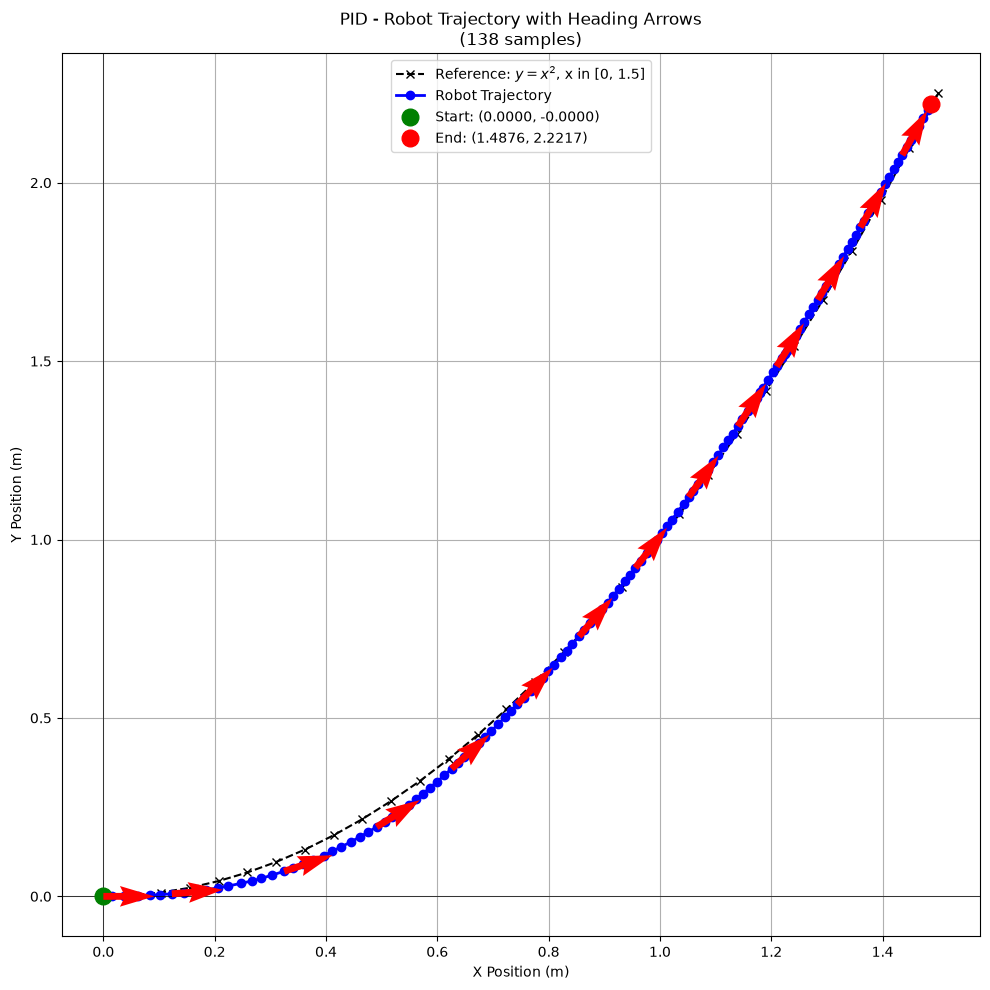

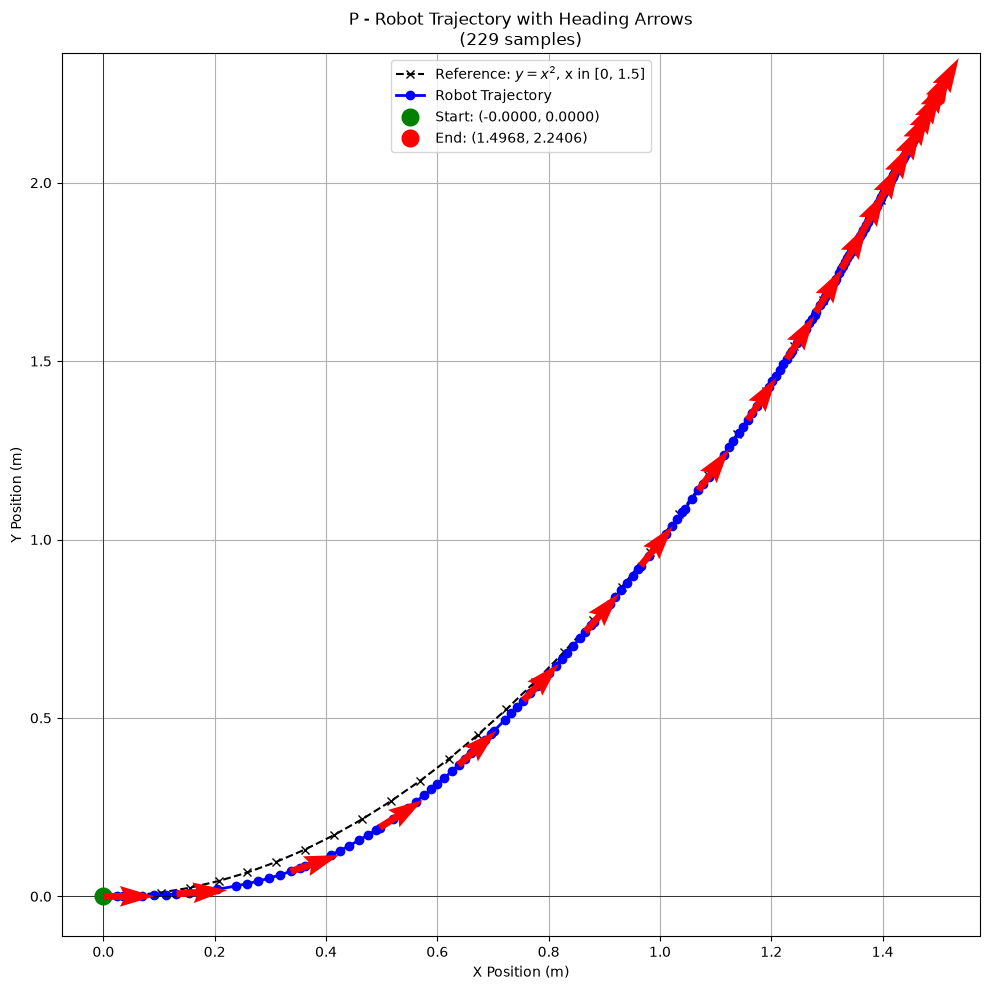

In [6]:
for name, run in runs.items():
    x_positions, y_positions, theta = run['x'], run['y'], run['theta']

    # Create arrow-based trajectory visualization
    fig, ax = plt.subplots(1, figsize=(10, 10))

    # Plot trajectory with arrows showing heading (theta) at every 10th point
    step = 10
    ax.quiver(x_positions[::step], y_positions[::step],
              np.cos(theta[::step]), np.sin(theta[::step]),
              angles='xy', color='r', zorder=3)

    # Draw reference and trajectory lines
    ax.plot(run['ref_x'], run['ref_y'], 'k--', marker='x', label=f"Reference: {run['ref_label']}")
    ax.plot(x_positions, y_positions, 'b-', marker='o', linewidth=2, label='Robot Trajectory')
    ax.set_xlabel('X Position (m)')
    ax.set_ylabel('Y Position (m)')
    ax.set_title(f'{name} - Robot Trajectory with Heading Arrows\n({len(theta)} samples)')
    ax.grid(True)
    ax.axhline(y=0, color='k', linewidth=0.5)
    ax.axvline(x=0, color='k', linewidth=0.5)

    # Add start and end points
    ax.plot(x_positions[0], y_positions[0], 'go', markersize=12,
           label=f'Start: ({x_positions[0]:.4f}, {y_positions[0]:.4f})')
    ax.plot(x_positions[-1], y_positions[-1], 'ro', markersize=12,
           label=f'End: ({x_positions[-1]:.4f}, {y_positions[-1]:.4f})')

    legend = ax.legend()
    legend.get_frame().set_alpha(0.8)

    plt.tight_layout()
    plt.show()

In [7]:
for name, run in runs.items():
    x_positions, y_positions, theta = run['x'], run['y'], run['theta']

    # Load and display run name from directory
    run_dir = os.path.basename(os.path.normpath(run['path']))
    print(f"[{name}] Run Directory: {run_dir}")
    print(f"Number of samples: {len(theta)}")
    print(f"Duration: {(run['stamp'][-1] - run['stamp'][0]) / 1e9:.2f} s")
    print(f"Initial position: x={x_positions[0]:.6f}, y={y_positions[0]:.6f}")
    print(f"Final position: x={x_positions[-1]:.6f}, y={y_positions[-1]:.6f}")
    print(f"Initial heading: {theta[0]:.6f} rad ({np.degrees(theta[0]):.2f}°)")
    print(f"Final heading: {theta[-1]:.6f} rad ({np.degrees(theta[-1]):.2f}°)")
    print()

[PID] Run Directory: trajectory_parabola_PID_20261028-181744
Number of samples: 138
Duration: 13.60 s
Initial position: x=0.000000, y=-0.000001
Final position: x=1.487610, y=2.221661
Initial heading: 0.000005 rad (0.00°)
Final heading: 1.228216 rad (70.37°)

[P] Run Directory: trajectory_parabola_P_20261028-173605
Number of samples: 229
Duration: 22.71 s
Initial position: x=-0.000000, y=0.000000
Final position: x=1.496803, y=2.240554
Initial heading: -0.000002 rad (-0.00°)
Final heading: 1.260928 rad (72.25°)



## Report figures

These cells make the three figures used in `report/report.tex` and save them as PDFs in `report/figures/`, plus the Table 1 metrics.
Robot data comes from `runs_submit/`. The PID point run is **simulated**: we skipped PID point runs in the lab, so `sim_point.py` runs our controller code on a robot model fitted to the P run 17:12:26. Recreate it with:

```
python3 sim_point.py --like runs_submit/point_P_20261028-170124_1 --controller PID \
    --gains-from runs_submit/trajectory_sigmoid_PID_20261028-182745 --name final_gains
python3 sim_point.py --like runs_submit/point_P_20261028-171226_2 --controller PID \
    --gains-from runs_submit/trajectory_sigmoid_PID_20261028-182745 --name final_gains
```

The only PID in this notebook and the report is our final PID ($k_{lp}=0.2$, $k_{lv}=0.05$, $k_{li}=0.025$, $k_{ap}=1.0$, $k_{av}=0.2$, $k_{ai}=0.025$):
on the robot in runs 18:17:44 (parabola) and 18:27:45 (sigmoid), and in the two simulated point runs above.

In [8]:
from matplotlib.lines import Line2D

FIG_DIR = "report/figures"
TEXT_WIDTH = 7.1   # in: letter paper with the 0.7 in margins of report.tex
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({
    "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8, "legend.fontsize": 7,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "lines.linewidth": 1.1,
    "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.5, "axes.edgecolor": "#888888",
    "legend.frameon": False, "legend.handlelength": 2.2, "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
})

# Colour = controller, the same in every figure
C_P, C_PID, C_PI = "#2a78d6", "#eb6834", "#1baf7a"
C_REF = "#555555"

def load_logs(run_path):
    """Pose and error logs of a run with time t (s) from the first pose sample, plus its params.json."""
    pose, lin, ang = (read_csv(os.path.join(run_path, f)) for f in ("robot_pose.csv", "linear.csv", "angular.csv"))
    t0 = pose['stamp'].iloc[0]
    for df in (pose, lin, ang):
        df['t'] = (df['stamp'] - t0) / 1e9
    with open(os.path.join(run_path, "params.json")) as f:
        params = json.load(f)
    return pose, lin, ang, params

def run_time(run_path):
    """HH:MM:SS start time of a run, from the end of its folder name (how the report names runs)."""
    stamp = next(part for part in os.path.basename(os.path.normpath(run_path)).split("_") if "-" in part)
    hhmmss = stamp.split("-")[1]
    return f"{hhmmss[:2]}:{hhmmss[2:4]}:{hhmmss[4:]}"

def distance_to_curve(x, y, curve, x_max, n=20000):
    """Distance from each pose to the nearest point of the continuous reference curve y(x)."""
    cx = np.linspace(0.0, x_max, n)
    cy = curve(cx)
    return np.array([np.hypot(xi - cx, yi - cy).min() for xi, yi in zip(x, y)])

def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name))
    plt.show()

### Figure 1: point controller, P on the robot vs PID simulated

Goal 1 m straight ahead, the same controller code (`controller` in controller.py) for both. PID is our final PID (gains copied from run 18:27:45). All states as {e-t, ė-t}, {x-t, y-t, θ-t}, {x-y} and {e-ė}.
A goal behind the robot is avoided: there the PID distance integral winds up during the turn and the robot circles the goal.

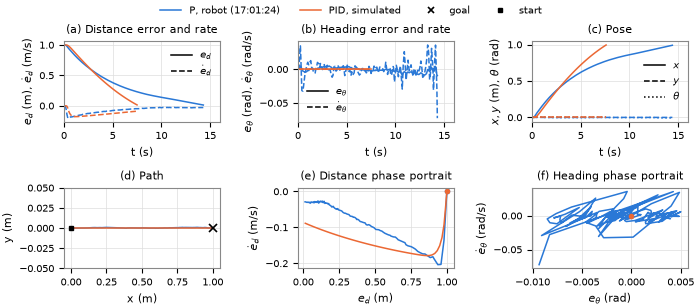

P, robot (17:01:24): goal after 14.4 s, speed command at the 0.22 m/s limit never, max |e_theta| 0.54 deg
PID, simulated: goal after 7.6 s, speed command at the 0.22 m/s limit never, max |e_theta| 0.00 deg


In [9]:
# Goal 1 m straight ahead, so neither controller has to turn (PID circles a goal behind the robot)
POINT_P = "runs_submit/point_P_20261028-170124_1"
# Our final PID: the gains of runs 18:17:44 and 18:27:45, copied from 18:27:45
SIM_PID = "sim_runs/sim_point_PID_like_point_P_20261028-170124_1_final_gains"
T_MAX = 16   # s shown

point_runs = {f"P, robot ({run_time(POINT_P)})": (load_logs(POINT_P), C_P),
              "PID, simulated": (load_logs(SIM_PID), C_PID)}

fig, axs = plt.subplots(2, 3, figsize=(TEXT_WIDTH, 3.05))
(ax_d, ax_h, ax_pose), (ax_path, ax_dphase, ax_hphase) = axs

for label, ((pose, lin, ang, params), color) in point_runs.items():
    pose, lin, ang = pose[pose.t <= T_MAX], lin[lin.t <= T_MAX], ang[ang.t <= T_MAX]

    # (a, b) {e-t, edot-t}: line style = quantity, colour = controller
    ax_d.plot(lin.t, lin.e, color=color, ls="-")
    ax_d.plot(lin.t, lin.e_dot, color=color, ls="--")
    ax_h.plot(ang.t, ang.e, color=color, ls="-")
    ax_h.plot(ang.t, ang.e_dot, color=color, ls="--")

    # (c) {x-t, y-t, th-t}
    ax_pose.plot(pose.t, pose.x, color=color, ls="-")
    ax_pose.plot(pose.t, pose.y, color=color, ls="--")
    ax_pose.plot(pose.t, pose.theta, color=color, ls=":")

    # (d) {x-y}
    ax_path.plot(pose.x, pose.y, color=color)

    # (e, f) {e-edot} phase portraits, start marked with a dot
    ax_dphase.plot(lin.e, lin.e_dot, color=color)
    ax_dphase.plot(lin.e.iloc[0], lin.e_dot.iloc[0], "o", color=color, ms=3)
    ax_hphase.plot(ang.e, ang.e_dot, color=color)
    ax_hphase.plot(ang.e.iloc[0], ang.e_dot.iloc[0], "o", color=color, ms=3)

goal = point_runs[f"P, robot ({run_time(POINT_P)})"][0][3]["goal"]
ax_path.plot(*goal, "x", color="k", ms=6, mew=1.2)
ax_path.plot(0, 0, "s", color="k", ms=3)
ax_path.set_ylim(-0.05, 0.05)

style_legend = lambda names, styles: [Line2D([], [], color="k", ls=s, label=n) for n, s in zip(names, styles)]
ax_d.legend(handles=style_legend([r"$e_d$", r"$\dot e_d$"], ["-", "--"]), loc="upper right")
ax_h.legend(handles=style_legend([r"$e_\theta$", r"$\dot e_\theta$"], ["-", "--"]), loc="lower left")
ax_pose.legend(handles=style_legend([r"$x$", r"$y$", r"$\theta$"], ["-", "--", ":"]), loc="center right")

titles = ["(a) Distance error and rate", "(b) Heading error and rate", "(c) Pose",
          "(d) Path", "(e) Distance phase portrait", "(f) Heading phase portrait"]
labels = [("t (s)", r"$e_d$ (m), $\dot e_d$ (m/s)"), ("t (s)", r"$e_\theta$ (rad), $\dot e_\theta$ (rad/s)"),
          ("t (s)", r"$x, y$ (m), $\theta$ (rad)"), ("x (m)", "y (m)"),
          (r"$e_d$ (m)", r"$\dot e_d$ (m/s)"), (r"$e_\theta$ (rad)", r"$\dot e_\theta$ (rad/s)")]
for ax, title, (xl, yl) in zip(axs.flat, titles, labels):
    ax.set_title(title)
    ax.set_xlabel(xl)
    ax.set_ylabel(yl)
for ax in (ax_d, ax_h, ax_pose):
    ax.set_xlim(0, T_MAX)

fig.legend(handles=[Line2D([], [], color=c, label=l) for l, (_, c) in point_runs.items()]
                   + [Line2D([], [], color="k", ls="", marker="x", ms=5, mew=1.2, label="goal"),
                      Line2D([], [], color="k", ls="", marker="s", ms=3, label="start")],
           loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.05))
fig.tight_layout()
save(fig, "fig_point_P.pdf")

# Numbers quoted in the caption
for label, ((pose, lin, ang, params), _) in point_runs.items():
    g = params["gains"]
    v_cmd = g["klp"] * lin.e + ((g["klv"] * lin.e_dot + g["kli"] * lin.e_int) if label.startswith("PID") else 0)
    at_limit = lin.t[v_cmd >= 0.22]
    print(f"{label}: goal after {pose.t.iloc[-1]:.1f} s, speed command at the 0.22 m/s limit "
          + (f"from {at_limit.iloc[0]:.1f} s to the goal" if len(at_limit) else "never")
          + f", max |e_theta| {np.degrees(np.abs(ang.e).max()):.2f} deg")

### Figure 2: tuning on the robot

Distance gain sweep (P, goal 1 m ahead) and heading gain sweep (P, goal behind). Colour lightness = gain.

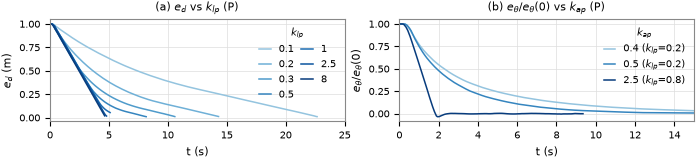

In [10]:
KLP_RUNS = ["point_P_20261028-165359_first_P_check", "point_P_20261028-170124_1", "point_P_20261028-165853_first_P_check",
            "point_P_20261028-164602_first_P_check", "point_P_20261028-162402_first_P_check",
            "point_P_20261028-162858_first_P_check", "point_P_20261028-163123_first_P_check"]   # klp 0.1 ... 8.0
KAP_RUNS = ["point_P_20261028-171849", "point_P_20261028-171226_2", "point_P_20261028-165531"]  # kap 0.4, 0.5, 2.5

ramp = lambda cmap, n: plt.get_cmap(cmap)(np.linspace(0.4, 0.95, n))   # light -> dark = low -> high gain

fig, (ax_klp, ax_kap) = plt.subplots(1, 2, figsize=(TEXT_WIDTH, 1.8))

# (a) distance error for each klp
for run, color in zip(KLP_RUNS, ramp("Blues", len(KLP_RUNS))):
    _, lin, _, params = load_logs(f"runs_submit/{run}")
    ax_klp.plot(lin.t, lin.e, color=color, label=f"{params['gains']['klp']:g}")
ax_klp.legend(title=r"$k_{lp}$", loc="upper right", ncol=2, title_fontsize=7, columnspacing=0.8, handlelength=1.2)

# (b) heading error, normalised by its start value
for run, color in zip(KAP_RUNS, ramp("Blues", len(KAP_RUNS))):
    _, _, ang, params = load_logs(f"runs_submit/{run}")
    label = rf"{params['gains']['kap']:g} ($k_{{lp}}$={params['gains']['klp']:g})"
    ax_kap.plot(ang.t, ang.e / ang.e.iloc[0], color=color, label=label)
ax_kap.legend(title=r"$k_{ap}$", loc="upper right", title_fontsize=7, handlelength=1.2)

for ax, title, xl, yl in [(ax_klp, r"(a) $e_d$ vs $k_{lp}$ (P)", "t (s)", r"$e_d$ (m)"),
                          (ax_kap, r"(b) $e_\theta / e_\theta(0)$ vs $k_{ap}$ (P)", "t (s)", r"$e_\theta / e_\theta(0)$")]:
    ax.set_title(title)
    ax.set_xlabel(xl)
    ax.set_ylabel(yl)
ax_klp.set_xlim(0, 25)
ax_kap.set_xlim(0, 15)
fig.tight_layout(w_pad=0.6)
save(fig, "fig_tuning.pdf")

### Figure 3: trajectories

{x-y} of the parabola (P, PI and our final PID at the same $k_{lp}$, $k_{ap}$) and the stretched sigmoid (final PID), and the distance from the reference curve.

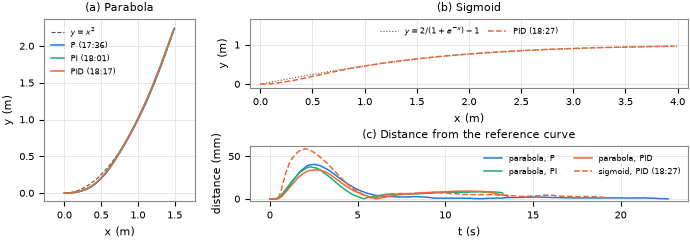

In [11]:
PARABOLA_RUNS = [("P", "runs_submit/trajectory_parabola_P_20261028-173605", C_P),
                 ("PI", "runs_submit/trajectory_parabola_PI_20261028-180156", C_PI),
                 ("PID", "runs_submit/trajectory_parabola_PID_20261028-181744", C_PID)]
SIGMOID_RUNS = [("PID", "runs_submit/trajectory_sigmoid_PID_20261028-182745", "--", ":")]   # run, reference line styles

fig = plt.figure(figsize=(TEXT_WIDTH, 2.6))
grid = fig.add_gridspec(2, 2, width_ratios=[1, 2.9], height_ratios=[1.25, 1])
ax_par, ax_sig, ax_dist = fig.add_subplot(grid[:, 0]), fig.add_subplot(grid[0, 1]), fig.add_subplot(grid[1, 1])

# (a) parabola
_, curve, x_max = REFERENCE_CURVES["parabola"][0]
cx = np.linspace(0, x_max, 200)
ax_par.plot(cx, curve(cx), color=C_REF, ls="--", lw=0.8, label=REFERENCE_CURVES["parabola"][0][0])
for name, run, color in PARABOLA_RUNS:
    pose = load_logs(run)[0]
    ax_par.plot(pose.x, pose.y, color=color, label=f"{name} ({run_time(run)[:5]})")
    d = distance_to_curve(pose.x.values, pose.y.values, curve, x_max)
    ax_dist.plot(pose.t, 1000 * d, color=color, label=f"parabola, {name}")
ax_par.set_aspect("equal", adjustable="datalim")
ax_par.legend(loc="upper left", fontsize=6, handlelength=1.5)

# (b) sigmoid: each run against the curve it followed (the planner was changed between them)
for name, run, ls, ref_ls in SIGMOID_RUNS:
    pose = load_logs(run)[0]
    ref_x, ref_y, ref_label = reference_path(run, pose.x.values, pose.y.values)
    label, curve, x_max = next(c for c in REFERENCE_CURVES["sigmoid"] if ref_label.startswith(c[0]))
    cx = np.linspace(0, x_max, 300)
    ax_sig.plot(cx, curve(cx), color=C_REF, ls=ref_ls, lw=0.8, label=label)
    ax_sig.plot(pose.x, pose.y, color=C_PID, ls=ls, label=f"{name} ({run_time(run)[:5]})")
    d = distance_to_curve(pose.x.values, pose.y.values, curve, x_max)
    ax_dist.plot(pose.t, 1000 * d, color=C_PID, ls=ls, label=f"sigmoid, {name} ({run_time(run)[:5]})")
ax_sig.set_xlim(-0.1, 4.1)
ax_sig.set_ylim(-0.1, 1.65)   # room for the legend above the curves
ax_sig.legend(loc="upper center", fontsize=6, ncol=2, columnspacing=1.0)
ax_dist.legend(loc="upper right", fontsize=6, ncol=2)

for ax, title, xl, yl in [(ax_par, "(a) Parabola", "x (m)", "y (m)"), (ax_sig, "(b) Sigmoid", "x (m)", "y (m)"),
                          (ax_dist, "(c) Distance from the reference curve", "t (s)", "distance (mm)")]:
    ax.set_title(title)
    ax.set_xlabel(xl)
    ax.set_ylabel(yl)
fig.tight_layout(h_pad=0.4, w_pad=0.8)
save(fig, "fig_trajectories.pdf")

### Table 1 and Figure 1 metrics: goal 1 m ahead

Goal 1 m ahead, so only the distance loop does anything. Rise time = distance from 90 % to 10 % of its start value, settling = last exit from ±5 %.
The logs stop when the robot is inside the goal tolerance; it then rolls on for the delay plus the lag of the robot model before it stops, which the roll estimate adds.

In [12]:
with open(os.path.join(SIM_PID, "params.json")) as f:
    model = json.load(f)["model"]
STOP_TIME = model["delay_s"] + model["tau_s"]   # s the robot keeps moving after the stop command (fitted model)

def point_metrics(run_path):
    pose, lin, ang, params = load_logs(run_path)
    gx, gy = params["goal"]
    t, dist = pose.t.values, np.hypot(pose.x - gx, pose.y - gy).values
    n = dist / dist[0]
    speed_at_goal = np.hypot(pose.x.diff(), pose.y.diff()).iloc[-1] / pose.t.diff().iloc[-1]
    along = (pose.x * gx + pose.y * gy).values / np.hypot(gx, gy)
    return {
        "distance rise 90->10% (s)": t[np.argmax(n <= 0.1)] - t[np.argmax(n <= 0.9)],
        "settling 5% (s)": t[np.where(n > 0.05)[0][-1] + 1],
        "time to goal (s)": t[-1],
        "error when stopping (mm)": 1000 * dist[-1],
        "speed at the goal (m/s)": speed_at_goal,
        "roll after stop, est. (mm)": 1000 * speed_at_goal * STOP_TIME,
        "roll after stop, est. (% of start distance)": 100 * speed_at_goal * STOP_TIME / dist[0],
        "ends past the goal, est. (mm)": 1000 * (speed_at_goal * STOP_TIME - (np.hypot(gx, gy) - along[-1])),
        "ends past the goal, est. (% of start distance)": 100 * (speed_at_goal * STOP_TIME - (np.hypot(gx, gy) - along[-1])) / dist[0],
        "overshoot past goal, logged (mm)": 1000 * max(0, along.max() - np.hypot(gx, gy)),
        "max sideways (mm)": 1000 * np.abs(-pose.x * np.sin(np.arctan2(gy, gx)) + pose.y * np.cos(np.arctan2(gy, gx))).max(),
        "max heading error (deg)": np.degrees(np.abs(ang.e).max()),
    }

metrics = pd.DataFrame({f"P, robot ({run_time(POINT_P)})": point_metrics(POINT_P), "PID, simulated": point_metrics(SIM_PID)})
metrics.round(3)

,"P, robot (17:01:24)","PID, simulated"
distance rise 90->10% (s),10.612,5.600
settling 5% (s),13.105,7.200
time to goal (s),14.401,7.600
error when stopping (mm),9.320,5.622
speed at the goal (m/s),0.032,0.086
"roll after stop, est. (mm)",14.506,38.773
"roll after stop, est. (% of start distance)",1.451,3.877
"ends past the goal, est. (mm)",5.186,33.152
"ends past the goal, est. (% of start distance)",0.519,3.315
"overshoot past goal, logged (mm)",0.000,0.000


## Numbers quoted in the report

Every measured or simulated number in `report/report.tex`, computed from the logs, in the order of the report.
Definitions: rise time = error from 90 % to 10 % of its start value; settling = last exit from ±5 %; fitted time constant = exponential
fitted to the error over that same 90 % → 10 % range; heading metrics leave out the last 15 cm (bearing ill-defined near the goal),
which also keeps the robot's 0.03 m/s minimum speed out of the distance fits.

In [13]:
def rise_time(t, e):
    n = np.abs(e) / abs(e[0])
    return t[np.argmax(n <= 0.1)] - t[np.argmax(n <= 0.9)] if (n <= 0.1).any() else np.nan

def settling_time(t, e, band=0.05):
    outside = np.where(np.abs(e) / abs(e[0]) > band)[0]
    return t[outside[-1] + 1] if outside[-1] + 1 < len(t) else np.nan

def fitted_time_constant(t, e, keep):
    """Time constant of an exponential fitted to |e| over 90 % -> 10 % of its start value, on the samples in keep."""
    n = np.abs(e) / abs(e[0])
    m = keep & (n < 0.9) & (n > 0.1)
    return -1 / np.polyfit(t[m], np.log(n[m]), 1)[0]

def speeds(pose):
    """Times (s) and speeds along the path (m/s) between pose samples."""
    dt = np.diff(pose.t.values)
    return pose.t.values[:-1] + dt / 2, np.hypot(np.diff(pose.x.values), np.diff(pose.y.values)) / dt

def first_motion(pose, threshold=0.002):
    """Time of the first pose more than threshold (m) from the start."""
    d = np.hypot(pose.x - pose.x.iloc[0], pose.y - pose.y.iloc[0]).values
    return pose.t.values[np.argmax(d > threshold)]

def max_sideways(pose, goal):
    """Largest distance (m) from the straight line through the start and the goal."""
    phi = np.arctan2(goal[1], goal[0])
    return np.abs(-pose.x * np.sin(phi) + pose.y * np.cos(phi)).max()

POINT_RUNS = sorted(r for r in os.listdir("runs_submit") if r.startswith("point_"))

### Setup paragraph: response delay and minimum speed

In [14]:
delays = pd.Series({run_time(r): first_motion(load_logs(f"runs_submit/{r}")[0]) for r in POINT_RUNS})
print(f"time from the first command to the first motion over the {len(delays)} point runs: "
      f"{delays.min():.2f} to {delays.max():.2f} s (median {delays.median():.2f} s)")

# The slowest runs end crawling: speed over their last 2 s, while the P command is below 0.03 m/s
for r in ["point_P_20261028-165359_first_P_check", "point_P_20261028-170124_1"]:
    pose, lin, _, p = load_logs(f"runs_submit/{r}")
    tm, v = speeds(pose)
    last = tm > tm[-1] - 2
    print(f"{run_time(r)} (klp {p['gains']['klp']}): command at the end {p['gains']['klp'] * lin.e.iloc[-1]:.3f} m/s, "
          f"measured speed over the last 2 s {np.median(v[last]):.3f} m/s (median)")

time from the first command to the first motion over the 23 point runs: 0.19 to 0.56 s (median 0.31 s)
16:53:59 (klp 0.1): command at the end 0.001 m/s, measured speed over the last 2 s 0.029 m/s (median)
17:01:24 (klp 0.2): command at the end 0.003 m/s, measured speed over the last 2 s 0.030 m/s (median)


### Figure 1 caption: extra numbers

In [15]:
pose, lin, _, p = load_logs(SIM_PID)
g = p["gains"]
command = g["klp"] * lin.e + g["klv"] * lin.e_dot + g["kli"] * lin.e_int
print(f"PID (simulated, goal ahead): peak speed command {command.max():.3f} m/s (limit 0.22)")

# The same final PID with the goal behind the robot (second sim_point.py command above): it never comes within the 1 cm tolerance
pose, _, _, p = load_logs("sim_runs/sim_point_PID_like_point_P_20261028-171226_2_final_gains")
d = np.hypot(pose.x - p["goal"][0], pose.y - p["goal"][1])
print(f"PID (simulated, goal behind, gains {p['gains']}): within 1 cm: {(d < 0.01).any()}, closest {1000 * d.min():.0f} mm, "
      f"{1000 * d[pose.t > 40].mean():.0f} mm from the goal after 40 s of {pose.t.iloc[-1]:.0f} s")

PID (simulated, goal ahead): peak speed command 0.207 m/s (limit 0.22)
PID (simulated, goal behind, gains {'klp': 0.2, 'klv': 0.05, 'kli': 0.025, 'kap': 1.0, 'kav': 0.2, 'kai': 0.025}): within 1 cm: False, closest 28 mm, 116 mm from the goal after 40 s of 60 s


### Tuning (a): distance gain, P, goal 1 m ahead

In [16]:
rows = {}
for r in KLP_RUNS:
    pose, lin, _, p = load_logs(f"runs_submit/{r}")
    klp = p["gains"]["klp"]
    t, e = lin.t.values, lin.e.values
    at_limit = klp * e >= 0.22
    rows[klp] = {
        "fitted time constant (s)": fitted_time_constant(t, e, e > 0.15) if klp <= 0.3 else np.nan,
        "1/klp (s)": 1 / klp,
        "command at the limit (s)": t[at_limit].max() - t[at_limit].min() + 0.1 if at_limit.any() else 0.0,
        "command leaves the limit at e_d (m)": e[at_limit][-1] if at_limit.any() else np.nan,
        "time to goal (s)": pose.t.iloc[-1],
        "goal tolerance (m)": p["goal_tolerance"],
    }
print(f"largest klp with klp * 1 m below 0.22 m/s: 0.22 / 1 m = {0.22:.2f} (we ran 0.2; 0.3 gives 0.3 m/s)")
pd.DataFrame(rows).round(2)

largest klp with klp * 1 m below 0.22 m/s: 0.22 / 1 m = 0.22 (we ran 0.2; 0.3 gives 0.3 m/s)


,0.1,0.2,0.3,0.5,1.0,2.5,8.0
fitted time constant (s),9.79,4.97,3.19,NaN,NaN,NaN,NaN
1/klp (s),10.00,5.00,3.33,2.00,1.00,0.40,0.12
command at the limit (s),0.00,0.00,1.49,2.96,3.90,4.50,4.64
command leaves the limit at e_d (m),NaN,NaN,0.74,0.44,0.24,0.09,0.04
time to goal (s),22.80,14.40,10.69,8.26,5.21,4.90,4.75
goal tolerance (m),0.01,0.01,0.01,0.01,0.05,0.01,0.01


### Tuning (b): heading gain, P, goal behind

In [17]:
print(f"180 deg turn: kap * pi stays below 1.9 rad/s for kap < {1.9 / np.pi:.2f}")
rows = {}
for r in KAP_RUNS:
    pose, lin, ang, p = load_logs(f"runs_submit/{r}")
    keep = lin.e.values > 0.15
    t, e = ang.t.values, ang.e.values
    rows[run_time(r)] = {
        "kap": p["gains"]["kap"], "klp": p["gains"]["klp"], "start heading error (deg)": np.degrees(e[0]),
        "max turn command (rad/s)": p["gains"]["kap"] * np.abs(e).max(),
        "fitted time constant (s)": fitted_time_constant(t, e, keep), "1/kap (s)": 1 / p["gains"]["kap"],
        "rise 90->10% (s)": rise_time(t[keep], e[keep]),
        "overshoot (%)": 100 * max(0, (-np.sign(e[0]) * e[keep]).max()) / abs(e[0]),
        "arc: max sideways (mm)": 1000 * max_sideways(pose, p["goal"]),
    }
pd.DataFrame(rows).round(2)

180 deg turn: kap * pi stays below 1.9 rad/s for kap < 0.60


,17:18:49,17:12:26,16:55:31
kap,0.40,0.50,2.50
klp,0.20,0.20,0.80
start heading error (deg),-180.00,180.00,-135.00
max turn command (rad/s),1.26,1.57,5.89
fitted time constant (s),4.06,2.60,0.68
1/kap (s),2.50,2.00,0.40
rise 90->10% (s),8.50,5.60,1.15
overshoot (%),0.00,0.00,3.41
arc: max sideways (mm),627.11,491.37,196.49


### Trajectories paragraph and Figure 3

In [18]:
parabola_runs = sorted(r for r in os.listdir("runs_submit") if r.startswith("trajectory_parabola"))
print(f"parabola runs in runs_submit: {len(parabola_runs)}")
print(f"P slows down over the last v_max / klp = 0.22 / 0.2 = {0.22 / 0.2:.1f} m")
print(f"tightest turn at full speed: v_max / w_max = 0.22 / 1.9 = {0.22 / 1.9:.2f} m")

def tracking(run, curve, x_max, end):
    pose, lin, _, p = load_logs(run)
    g, ctype = p["gains"], p["controller"]
    v_cmd = (g["klp"] * lin.e + (g["kli"] * lin.e_int if ctype in ("PI", "PID") else 0)
             + (g["klv"] * lin.e_dot if ctype in ("PD", "PID") else 0))
    d = distance_to_curve(pose.x.values, pose.y.values, curve, x_max)
    to_end = np.hypot(pose.x - end[0], pose.y - end[1]).values
    return {"RMS distance (mm)": 1000 * np.sqrt((d ** 2).mean()), "worst distance (mm)": 1000 * d.max(),
            "worst at x (m)": pose.x.values[d.argmax()], "within 5 cm of the end after (s)": pose.t.values[np.argmax(to_end < 0.05)],
            "duration (s)": pose.t.iloc[-1], "goal tolerance (m)": p["goal_tolerance"],
            "speed command at 0.22 limit (%)": 100 * (v_cmd >= 0.22).mean()}

_, curve, x_max = REFERENCE_CURVES["parabola"][0]
rows = {f"parabola {name} {run_time(run)}": tracking(run, curve, x_max, (x_max, curve(x_max))) for name, run, _ in PARABOLA_RUNS}
rows["parabola P kap 3.0 17:31:40"] = tracking("runs_submit/trajectory_parabola_P_20261028-173140", curve, x_max, (x_max, curve(x_max)))
for label, scurve, sx_max in REFERENCE_CURVES["sigmoid"]:
    print(f"{label}, x in [0, {sx_max:g}]: leaves the origin at {np.degrees(np.arctan((scurve(1e-6) - scurve(0)) / 1e-6)):.0f} deg")
for name, run, _, _ in SIGMOID_RUNS:
    pose = load_logs(run)[0]
    ref_label = reference_path(run, pose.x.values, pose.y.values)[2]
    label, scurve, sx_max = next(c for c in REFERENCE_CURVES["sigmoid"] if ref_label.startswith(c[0]))
    rows[f"sigmoid {name} {run_time(run)}"] = tracking(run, scurve, sx_max, (sx_max, scurve(sx_max)))
pd.DataFrame(rows).T.round(2)

parabola runs in runs_submit: 16
P slows down over the last v_max / klp = 0.22 / 0.2 = 1.1 m
tightest turn at full speed: v_max / w_max = 0.22 / 1.9 = 0.12 m
$y = 2/(1+e^{-2x}) - 1$, x in [0, 2.5]: leaves the origin at 45 deg
$y = 2/(1+e^{-x}) - 1$, x in [0, 4]: leaves the origin at 27 deg


,RMS distance (mm),worst distance (mm),worst at x (m),within 5 cm of the end after (s),duration (s),goal tolerance (m),speed command at 0.22 limit (%)
parabola P 17:36:05,12.66,40.45,0.42,21.30,22.71,0.01,37.28
parabola PI 18:01:56,15.01,37.40,0.40,13.28,13.28,0.05,100.00
parabola PID 18:17:44,14.65,34.18,0.44,13.60,13.60,0.05,100.00
parabola P kap 3.0 17:31:40,4.98,7.96,0.72,21.79,23.11,0.01,38.05
sigmoid PID 18:27:45,20.05,58.63,0.30,19.36,19.36,0.05,100.00


In [19]:
# PI with a 1 cm tolerance at the end of the parabola: does it circle?
_, curve, x_max = REFERENCE_CURVES["parabola"][0]
end = (x_max, curve(x_max))
rows = {}
for r in ["trajectory_parabola_PI_20261028-174949", "trajectory_parabola_PI_20261028-175325"]:
    pose, lin, _, p = load_logs(f"runs_submit/{r}")
    g = p["gains"]
    near = (np.hypot(pose.x - end[0], pose.y - end[1]) < 0.15).values
    turned = np.abs(np.diff(np.unwrap(pose.theta.values))[near[1:]]).sum()
    v_cmd = g["klp"] * lin.e + g["kli"] * lin.e_int
    rows[run_time(r)] = {"kli": g["kli"], "goal tolerance (m)": p["goal_tolerance"],
                         "time within 15 cm of the end (s)": 0.1 * near.sum(), "turned there (deg)": np.degrees(turned),
                         "speed command there (m/s, median)": np.median(v_cmd.values[near[:len(v_cmd)]]),
                         "final distance to the end (mm)": 1000 * np.hypot(pose.x.iloc[-1] - end[0], pose.y.iloc[-1] - end[1])}
pd.DataFrame(rows).round(2)

,17:49:49,17:53:25
kli,0.05,0.02
goal tolerance (m),0.01,0.01
time within 15 cm of the end (s),2.20,7.90
turned there (deg),136.95,712.05
"speed command there (m/s, median)",0.97,0.53
final distance to the end (mm),9.76,119.85


### Section 2: stability analysis

Linear model of each loop with the robot's lag (τ = 0.2 s) and our final PID gains: `expected_pid.py`.


In [20]:
%run expected_pid.py
print(f"heading P loop critically damped (zeta = 1) at kap = 1 / (4 tau) = {1 / (4 * TAU):.2f}")
print(f"distance per control period at full speed: 0.22 m/s * 0.1 s = {0.22 * 0.1 * 1000:.0f} mm")

distance loop, start 1 m
P              rise 10.54 s  settle 5%  14.6 s  overshoot  0.0 %
PID            rise  5.51 s  settle 5%  27.9 s  overshoot 25.2 %  zero at 7.34 s (rate 0.080)  peak at 14.7 s
heading loop, start 180 deg
P              rise  1.77 s  settle 5%   2.5 s  overshoot  0.0 %
PD             rise  2.27 s  settle 5%   3.2 s  overshoot  0.0 %
PID            rise  2.11 s  settle 5%   2.9 s  overshoot  2.6 %  zero at 3.89 s (rate 0.088)  peak at  7.7 s

distance PID zeta 0.62, kli for zeta 0.7: 0.019
heading PID roots [-0.808 -0.026], slow time constant 38.8 s
heading P zeta: kap 0.4 1.77, kap 0.5 1.58, kap 1.0 1.12, PD 1.34
heading P kap 2.5: zeta 0.71, overshoot 4.3 %
heading P loop critically damped (zeta = 1) at kap = 1 / (4 tau) = 1.25
distance per control period at full speed: 0.22 m/s * 0.1 s = 22 mm
